[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L1/BA_L1_missing/BA_L1_missing.ipynb)

# BA_L1_missing: Coverage and Missing Values, Coin by Coin

*Quantlet of Lecture 1, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Share of days with no value in the daily transactions file of eleven coins, by coin and calendar year, November 2014 to 8 October 2025, and the period in which all eleven coins are observed.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts


def load_onchain(name):
    # daily on-chain series, one column per coin, as numbers (missing values are NaN)
    return onchain(name).apply(pd.to_numeric, errors='coerce')


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))

## Data and method

The transactions file has one column per coin: BTC (Bitcoin), ETH (Ethereum), DOGE (Dogecoin), ETC (Ethereum Classic),
XRP, LTC (Litecoin), BCH (Bitcoin Cash), ZEC (Zcash), BSV (Bitcoin SV), DASH (Dash) and XMR (Monero). For each coin
and each calendar year the cell computes the share of days without a value.

**How to read the chart.** White: complete; red: no value at all. Most gaps lie before a coin's first value; a gap
after it (XRP from 2023) means the source stopped reporting. The common period of all coins is the largest balanced
panel the file allows.

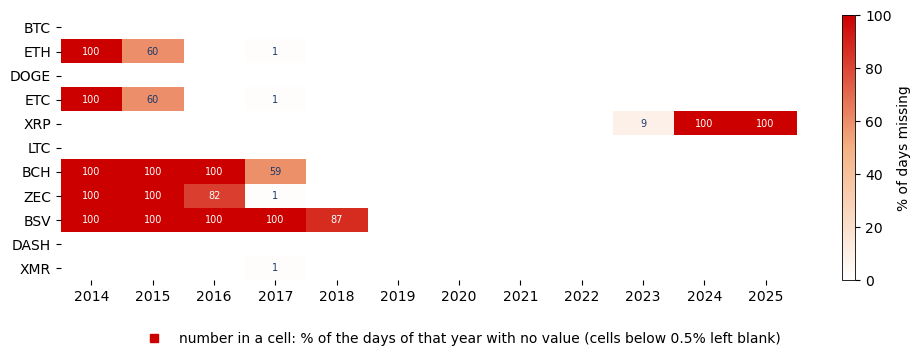

11 coins, 28 Nov 2014 - 08 Oct 2025
Coins complete in every year from their first value on: BTC, DOGE, LTC, BSV, DASH
Missing after the first value (%): BTC 0.0, ETH 0.1, DOGE 0.0, ETC 0.1, XRP 17.2, LTC 0.0, BCH 0.1, ZEC 0.2, BSV 0.0, DASH 0.0, XMR 0.1
All 11 coins have a value only from 15 November 2018 to 27 November 2023
XRP missing by year (%): 2023 9, 2024 100, 2025 100


In [5]:
# share of missing days per coin and calendar year, transactions file
tx_all = load_onchain('transaction')
miss = 100 * tx_all.isna().groupby(tx_all.index.year).mean().T
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('miss', ['#FFFFFF', '#F4B183', RED])

fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(miss.values, aspect='auto', cmap=cmap, vmin=0, vmax=100)
ax.set_xticks(range(miss.shape[1])); ax.set_xticklabels(miss.columns)
ax.set_yticks(range(miss.shape[0])); ax.set_yticklabels(miss.index)
for i in range(miss.shape[0]):
    for j in range(miss.shape[1]):
        v = miss.values[i, j]
        if v >= 0.5:
            ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=7, color='white' if v > 60 else BLUE)
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax).set_label('% of days missing')
ax.plot([], [], 's', color=RED, label='number in a cell: % of the days of that year with no value (cells below 0.5% left blank)')
legend_below(fig, ncol=1, bottom=0.10)
save_fig(fig, 'ba_l1_missing')

print(f'{tx_all.shape[1]} coins, {tx_all.index.min():%d %b %Y} - {tx_all.index.max():%d %b %Y}')
print('Coins complete in every year from their first value on:',
      ', '.join(c for c in tx_all if tx_all[c].loc[tx_all[c].first_valid_index():].isna().sum() == 0))
print('Missing after the first value (%):', ', '.join(f'{c} {100 * tx_all[c].loc[tx_all[c].first_valid_index():].isna().mean():.1f}' for c in tx_all))
print(f'All 11 coins have a value only from {tx_all.apply(lambda s: s.first_valid_index()).max():%d %B %Y} '
      f'to {tx_all.apply(lambda s: s.last_valid_index()).min():%d %B %Y}')
print('XRP missing by year (%):', ', '.join(f'{y} {v:.0f}' for y, v in miss.loc['XRP'].items() if v > 0))